# Day 18: Capstone build, part 1


## Setup

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, roc_curve, confusion_matrix, classification_report
import joblib

pd.set_option("display.max_columns", 30)

## Load the dataset

Using the IBM Telco Customer Churn dataset. It has one row per customer with their account details, the services they subscribed to, and whether they churned.

In [ ]:
url = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
df = pd.read_csv(url)
print(df.shape)
df.head()

(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


## Cleaning

TotalCharges comes in as text and has a handful of blanks, these are new customers with zero tenure. customerID is just an identifier so it gets dropped, and the target gets mapped to 0 and 1.

In [ ]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
df["TotalCharges"] = df["TotalCharges"].fillna(df["MonthlyCharges"] * df["tenure"])
df = df.drop(columns=["customerID"])
df["Churn"] = df["Churn"].map({"Yes": 1, "No": 0})
df["Churn"].value_counts(normalize=True)

,proportion
Churn,
0,0.73463
1,0.26537


## EDA, the story behind the numbers

Rather than plotting every column, this looks at the handful of things most likely to explain why someone leaves: contract type, how long they have been a customer, and what they pay.

Overall churn rate: 26.5%


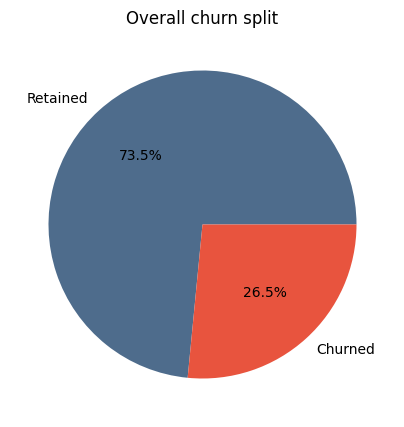

In [ ]:
churn_rate = df["Churn"].mean()
print(f"Overall churn rate: {churn_rate:.1%}")

fig, ax = plt.subplots(figsize=(5, 5))
df["Churn"].value_counts().sort_index().plot(
    kind="pie", labels=["Retained", "Churned"], autopct="%.1f%%",
    colors=["#4E6C8C", "#E8543E"], ylabel="")
plt.title("Overall churn split")
plt.show()

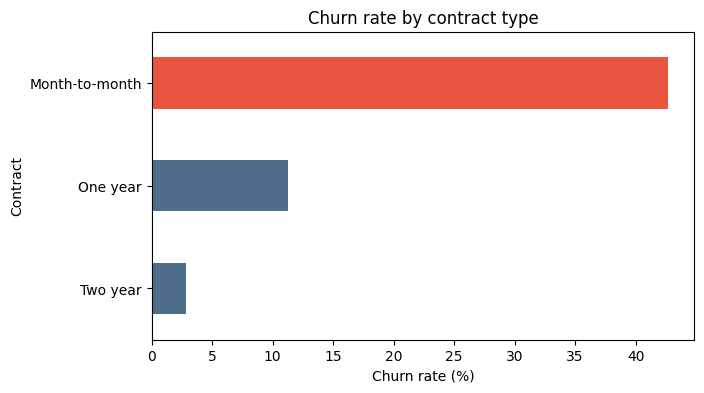

,Churn
Contract,
Two year,2.831858
One year,11.269518
Month-to-month,42.709677


In [ ]:
rate_by_contract = df.groupby("Contract")["Churn"].mean().sort_values() * 100

fig, ax = plt.subplots(figsize=(7, 4))
rate_by_contract.plot(kind="barh", color=["#4E6C8C", "#4E6C8C", "#E8543E"], ax=ax)
ax.set_xlabel("Churn rate (%)")
ax.set_title("Churn rate by contract type")
plt.show()

rate_by_contract

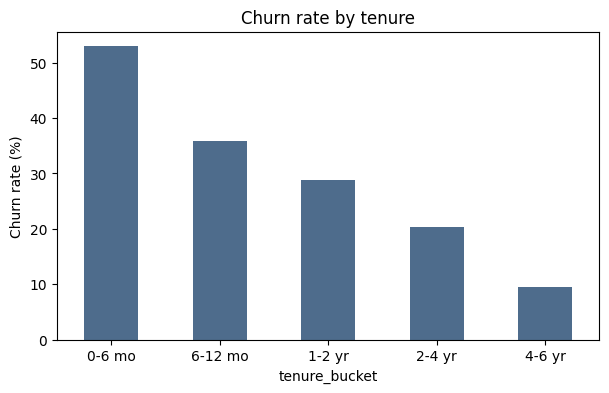

In [ ]:
bins = [0, 6, 12, 24, 48, 72]
labels = ["0-6 mo", "6-12 mo", "1-2 yr", "2-4 yr", "4-6 yr"]
df["tenure_bucket"] = pd.cut(df["tenure"], bins=bins, labels=labels, include_lowest=True)

rate_by_tenure = df.groupby("tenure_bucket", observed=True)["Churn"].mean() * 100

fig, ax = plt.subplots(figsize=(7, 4))
rate_by_tenure.plot(kind="bar", color="#4E6C8C", ax=ax)
ax.set_ylabel("Churn rate (%)")
ax.set_title("Churn rate by tenure")
plt.xticks(rotation=0)
plt.show()

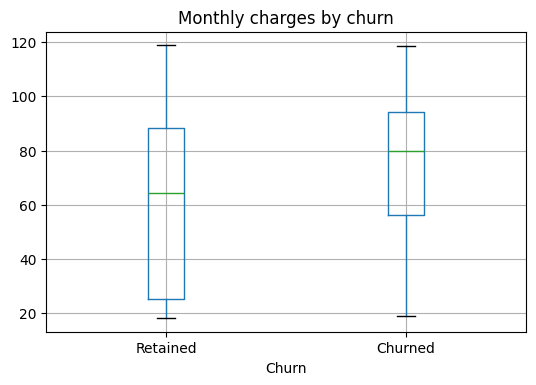

In [ ]:
fig, ax = plt.subplots(figsize=(6, 4))
df.boxplot(column="MonthlyCharges", by="Churn", ax=ax)
ax.set_xticklabels(["Retained", "Churned"])
plt.title("Monthly charges by churn")
plt.suptitle("")
plt.show()

**What this is telling us**

Month to month customers churn at roughly 43 percent versus under 3 percent for two year contracts, that alone is one of the strongest signals in the dataset. Newer customers churn far more than long tenured ones, the first six months are clearly the highest risk window. Churned customers also skew toward higher monthly charges, so price sensitivity is likely part of the story too. These three observations are going to matter a lot once we look at feature importance tomorrow.

## Preprocessing pipeline

Splitting into train and test first, before fitting anything, so there is no leakage from the test set into scaling or encoding.

In [ ]:
target = df["Churn"]
features = df.drop(columns=["Churn", "tenure_bucket"])

cat_cols = features.select_dtypes(include="object").columns.tolist()
num_cols = features.select_dtypes(exclude="object").columns.tolist()

X_train, X_test, y_train, y_test = train_test_split(
    features, target, test_size=0.2, stratify=target, random_state=42)

print(X_train.shape, X_test.shape)

(5634, 19) (1409, 19)


In [ ]:
preprocessor = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
])

## Baseline model

Logistic regression with class weighting to account for the roughly 27 percent churn rate. This is not meant to be the final model, it is here to prove the pipeline works end to end before we spend tomorrow tuning stronger models.

In [ ]:
baseline = Pipeline([
    ("pre", preprocessor),
    ("clf", LogisticRegression(max_iter=2000, class_weight="balanced")),
])

baseline.fit(X_train, y_train)
proba = baseline.predict_proba(X_test)[:, 1]
preds = baseline.predict(X_test)

print("ROC-AUC:", round(roc_auc_score(y_test, proba), 4))
print(classification_report(y_test, preds))

ROC-AUC: 0.8416
              precision    recall  f1-score   support

           0       0.90      0.72      0.80      1035
           1       0.50      0.78      0.61       374

    accuracy                           0.74      1409
   macro avg       0.70      0.75      0.71      1409
weighted avg       0.80      0.74      0.75      1409



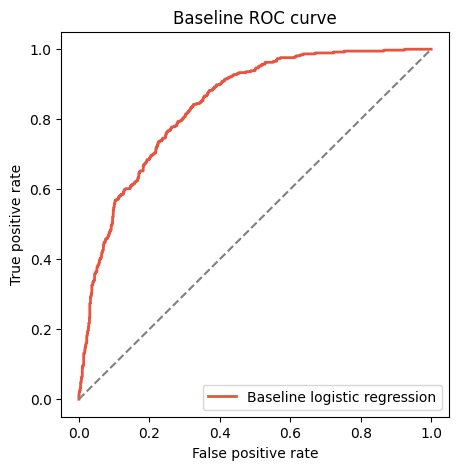

In [ ]:
fpr, tpr, _ = roc_curve(y_test, proba)
fig, ax = plt.subplots(figsize=(5, 5))
ax.plot(fpr, tpr, color="#E8543E", linewidth=2, label="Baseline logistic regression")
ax.plot([0, 1], [0, 1], linestyle="--", color="gray")
ax.set_xlabel("False positive rate")
ax.set_ylabel("True positive rate")
ax.legend()
plt.title("Baseline ROC curve")
plt.show()

## Saving today's work

Saving the cleaned dataframe and the baseline model so tomorrow's notebook can start from here without redoing all of this. Colab sessions reset, so this also gets pushed to the repo at wrap up.

In [ ]:
joblib.dump(baseline, "baseline_model.pkl")
df.to_csv("telco_clean.csv", index=False)
print("saved baseline_model.pkl and telco_clean.csv")

saved baseline_model.pkl and telco_clean.csv
